# 09 · Late Delivery: Evaluation and Business Impact

**Project:** Enterprise Supply Chain Intelligence Platform (DataCo)

Notebook 08 selected a model using training and validation evidence. This notebook asks two further questions:

1. **Does it hold up on orders it has never seen?** A single, final evaluation on the test period, plus calibration, stability over time, error analysis and feature drivers.
2. **Would it actually help a logistics team?** The scores are turned into a review queue, an operating point and an illustrative value estimate, with every assumption stated and editable.

**Order of work**
- The decision threshold is chosen on the **validation** period (section 2), so the test period never influences it.
- The **test** period is then used once to evaluate (section 3 onward).
- Business figures use placeholder cost assumptions. They show how to reason about value, and should be replaced with real operating numbers.

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)

# ---- Paths (Windows): same locations as notebooks 07 and 08 ----
PROJECT_ROOT = Path('E:/Supply Chain Project')
DATA_DIR   = PROJECT_ROOT / 'Datasets/Model Input'
MODEL_DIR  = PROJECT_ROOT / 'Models'
FIG_DIR    = PROJECT_ROOT / 'Reports/Figures'
REPORT_DIR = PROJECT_ROOT / 'Reports'

assert (DATA_DIR / 'model_input.csv.gz').is_file(), 'Run notebook 07 first.'
assert (MODEL_DIR / 'selected_model.joblib').is_file(), 'Run notebook 08 first.'
for folder in (MODEL_DIR, FIG_DIR, REPORT_DIR):
    assert not folder.is_file(), f'{folder} is a file. It must be a folder.'
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42

def savefig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Load the selected model and the data

In [2]:
from datetime import datetime

# ---- Guard: make sure notebook 07 has been run and its outputs are current ----
csv_path = DATA_DIR / 'model_input.csv.gz'
man_path = DATA_DIR / 'feature_manifest.json'
for p in (csv_path, man_path):
    assert p.is_file(), f'Missing {p.name} in {DATA_DIR}. Run notebook 07 first.'

with open(man_path) as f:
    manifest = json.load(f)
header = pd.read_csv(csv_path, nrows=0).columns.tolist()

problems = []
if 'split' not in header:
    problems.append("model_input.csv.gz has no 'split' column")
if 'evaluation_boundaries' not in manifest:
    problems.append("feature_manifest.json has no 'evaluation_boundaries' entry")
if problems:
    stamp = datetime.fromtimestamp(csv_path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
    raise RuntimeError(
        'Notebook 07 outputs are out of date (model_input.csv.gz was written ' + stamp + ').\n'
        + 'Problems: ' + '; '.join(problems) + '.\n'
        + 'Fix: open 07_late_delivery_data_audit_leakage_control.ipynb, choose Restart and Run All, '
        + 'check that its last cell prints "Verified", then run this notebook again.\n'
        + 'Folder checked: ' + str(DATA_DIR))

art = joblib.load(MODEL_DIR / 'selected_model.joblib')
model = art['pipeline']
FEATURES, NUM, CAT, TARGET = art['features'], art['numeric_features'], art['categorical_features'], art['target']

with open(DATA_DIR / 'feature_manifest.json') as f:
    manifest = json.load(f)
DATE_COL, ORDER_ID = manifest['date_col'], manifest['order_id']

data = pd.read_csv(DATA_DIR / 'model_input.csv.gz', parse_dates=[DATE_COL])
train = data[data['split'] == 'train']
val   = data[data['split'] == 'validation']
test  = data[data['split'] == 'test'].copy()

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print('Selected model:', art['selected_name'])
print('Best params   :', art['best_params'])
pd.DataFrame(manifest['evaluation_boundaries']).T

Selected model: Logistic Regression (tuned)
Best params   : {'clf__C': 10.0}


,rows,from,to,late_rate
train,122752,2015-01-01,2016-12-17,0.5491
validation,21664,2016-12-17,2017-04-22,0.5469
test,36103,2017-04-22,2018-01-31,0.5465


## 2. Threshold analysis (validation period only)

About 55% of orders are late, so the default 0.5 cutoff is a poor fit for how this model would be used. A cost-ratio rule does not work well either: with a base rate this high, flagging every order is almost always the cheapest option, which makes the model pointless.

So I use an operating rule a logistics team can reason about: **when the system flags an order as late, it should be right at least 80% of the time.** That keeps expedite and review effort from being spent on orders that were fine. Among all thresholds that meet the rule, I pick the one that catches the most late orders (highest recall).

The 80% target is an assumption and is a single parameter below.

In [3]:
TARGET_PRECISION = 0.80      # editable operating rule

def choose_threshold(y_true, proba, target_precision=TARGET_PRECISION):
    # Lowest threshold whose precision meets the target (= highest recall).
    # Falls back to the F1-optimal threshold if the target cannot be reached.
    if np.unique(proba).size == 1:
        return 0.5, 'constant scores'
    grid = np.unique(np.quantile(proba, np.linspace(0.01, 0.99, 197)))
    best, fallback, best_f1 = None, 0.5, -1
    for t in grid:
        pred = (proba >= t).astype(int)
        if pred.sum() == 0:
            continue
        p = precision_score(y_true, pred, zero_division=0)
        f = f1_score(y_true, pred)
        if f > best_f1:
            best_f1, fallback = f, t
        if p >= target_precision and best is None:
            best = t            # grid is ascending, so the first hit has the highest recall
    if best is not None:
        return best, 'precision target met'
    return fallback, 'fallback: F1-optimal'

val_proba = model.predict_proba(X_val)[:, 1]
THRESHOLD, how = choose_threshold(y_val, val_proba)
print(f'Chosen threshold: {THRESHOLD:.3f}  ({how})')

# alternative operating points, shown on validation only
ops = []
for tp_ in (0.70, 0.80, 0.90):
    t_, how_ = choose_threshold(y_val, val_proba, tp_)
    pr = (val_proba >= t_).astype(int)
    ops.append({'precision_target': tp_, 'threshold': round(t_, 3), 'note': how_,
                'val_precision': precision_score(y_val, pr, zero_division=0),
                'val_recall': recall_score(y_val, pr), 'val_flagged_share': pr.mean()})
pd.DataFrame(ops).round(3)

Chosen threshold: 0.459  (precision target met)


,precision_target,threshold,note,val_precision,val_recall,val_flagged_share
0,0.7,0.424,precision target met,0.701,0.667,0.520
1,0.8,0.459,precision target met,0.802,0.572,0.390
2,0.9,0.796,precision target met,0.902,0.371,0.225


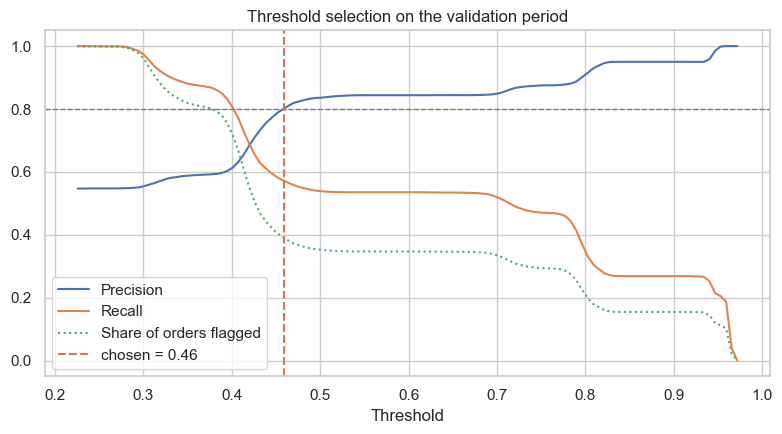

In [4]:
grid = np.linspace(val_proba.min(), val_proba.max(), 120)
sweep = pd.DataFrame({
    'threshold': grid,
    'precision': [precision_score(y_val, (val_proba >= t).astype(int), zero_division=0) for t in grid],
    'recall':    [recall_score(y_val, (val_proba >= t).astype(int)) for t in grid],
    'flagged_share': [(val_proba >= t).mean() for t in grid],
})
plt.figure(figsize=(8, 4.5))
plt.plot(sweep['threshold'], sweep['precision'], label='Precision')
plt.plot(sweep['threshold'], sweep['recall'], label='Recall')
plt.plot(sweep['threshold'], sweep['flagged_share'], label='Share of orders flagged', ls=':')
plt.axhline(TARGET_PRECISION, color='grey', ls='--', lw=1)
plt.axvline(THRESHOLD, color='#e76f51', ls='--', label=f'chosen = {THRESHOLD:.2f}')
plt.title('Threshold selection on the validation period'); plt.xlabel('Threshold'); plt.legend()
plt.tight_layout(); savefig('08_threshold_selection'); plt.show()

## 3. Final evaluation on the test period

Everything up to here used only train and validation data. The test period is used once, with the model and the threshold already fixed. The baselines are scored the same way, with their own thresholds chosen on validation by the same rule, so the comparison is fair.

In [5]:
def metrics_at(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {
        'roc_auc':   roc_auc_score(y_true, proba),
        'pr_auc':    average_precision_score(y_true, proba),
        'accuracy':  accuracy_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall':    recall_score(y_true, pred),
        'f1':        f1_score(y_true, pred),
        'brier':     brier_score_loss(y_true, proba),
        'flagged_share': pred.mean(),
    }

# planner-rule baseline, rebuilt from the training period
rule_cols = [c for c in NUM if c.startswith('Shipping Mode_') or c == 'Days for shipment (scheduled)']
rule_pre = ColumnTransformer([('r', Pipeline([('i', SimpleImputer(strategy='median')),
                                              ('s', StandardScaler())]), rule_cols)])
planner_rule = Pipeline([('pre', rule_pre), ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)

test_proba = model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

thr_rule, _ = choose_threshold(y_val, planner_rule.predict_proba(X_val)[:, 1])
results = pd.DataFrame({
    'Majority class': metrics_at(y_test, np.full(len(y_test), y_train.mean()), 0.5),
    'Planner rule (mode + scheduled days)': metrics_at(y_test, planner_rule.predict_proba(X_test)[:, 1], thr_rule),
    f'FINAL: {art["selected_name"]}': metrics_at(y_test, test_proba, THRESHOLD),
}).T
results.round(4)

,roc_auc,pr_auc,accuracy,precision,recall,f1,brier,flagged_share
Majority class,0.5000,0.5465,0.5465,0.5465,1.0000,0.7068,0.2478,1.0000
Planner rule (mode + scheduled days),0.7273,0.7451,0.6921,0.8421,0.5374,0.6561,0.1976,0.3488
FINAL: Logistic Regression (tuned),0.7371,0.8107,0.6919,0.8046,0.5762,0.6715,0.1971,0.3914


Threshold used: 0.459

True negatives  (on time, predicted on time): 13,609
False positives (on time, flagged late):      2,762
False negatives (late, missed):               8,362
True positives  (late, caught):               11,370


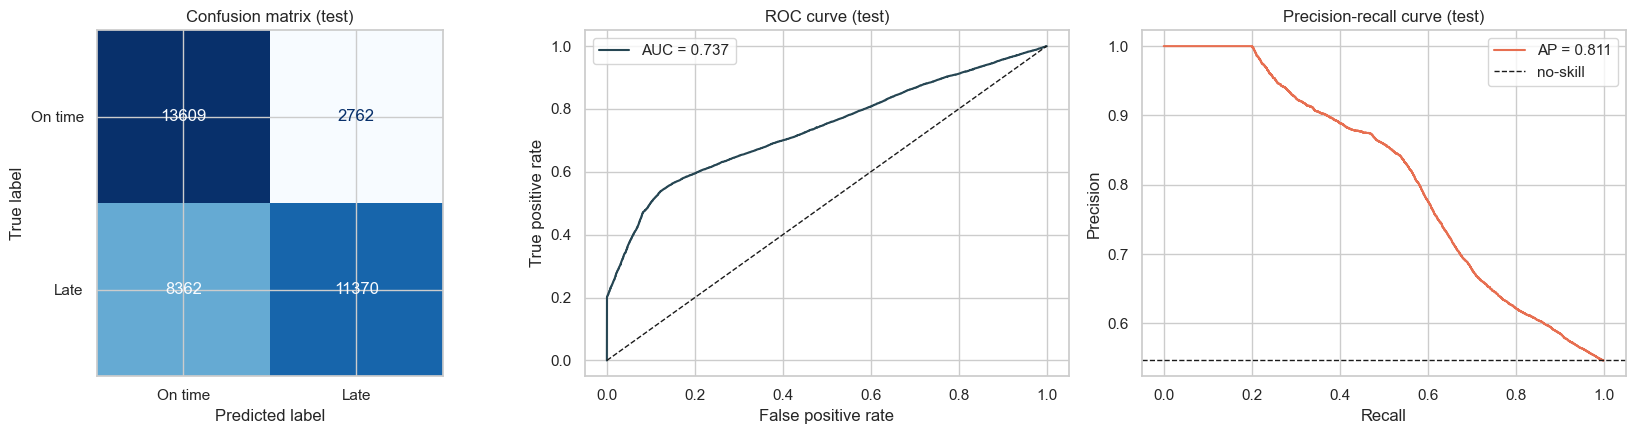

In [6]:
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
print(f'Threshold used: {THRESHOLD:.3f}\n')
print(f'True negatives  (on time, predicted on time): {tn:,}')
print(f'False positives (on time, flagged late):      {fp:,}')
print(f'False negatives (late, missed):               {fn:,}')
print(f'True positives  (late, caught):               {tp:,}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, ax=ax[0], cmap='Blues', colorbar=False,
                                        display_labels=['On time', 'Late'])
ax[0].set_title('Confusion matrix (test)')

fpr, tpr, _ = roc_curve(y_test, test_proba)
ax[1].plot(fpr, tpr, color='#264653', label=f'AUC = {roc_auc_score(y_test, test_proba):.3f}')
ax[1].plot([0, 1], [0, 1], 'k--', lw=1)
ax[1].set_title('ROC curve (test)'); ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].legend()

prec, rec, _ = precision_recall_curve(y_test, test_proba)
ax[2].plot(rec, prec, color='#e76f51', label=f'AP = {average_precision_score(y_test, test_proba):.3f}')
ax[2].axhline(y_test.mean(), color='k', ls='--', lw=1, label='no-skill')
ax[2].set_title('Precision-recall curve (test)'); ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].legend()
plt.tight_layout(); savefig('09_test_performance'); plt.show()

### 3.1 Did the validation threshold carry over?

The threshold was fixed on validation, so test precision may land a little above or below the 80% target. A small difference is normal. A large one would mean the score distribution shifted between periods.

In [7]:
val_pred = (val_proba >= THRESHOLD).astype(int)
pd.DataFrame({
    'precision': [precision_score(y_val, val_pred, zero_division=0), precision_score(y_test, test_pred, zero_division=0)],
    'recall':    [recall_score(y_val, val_pred), recall_score(y_test, test_pred)],
    'flagged_share': [val_pred.mean(), test_pred.mean()],
}, index=['validation (threshold chosen here)', 'test (first and only use)']).round(3)

,precision,recall,flagged_share
validation (threshold chosen here),0.802,0.572,0.390
test (first and only use),0.805,0.576,0.391


## 4. Are the probabilities trustworthy? Calibration

If the model says 80%, roughly 80% of those orders should be late. That matters when the score feeds a workflow and not just a yes/no flag.

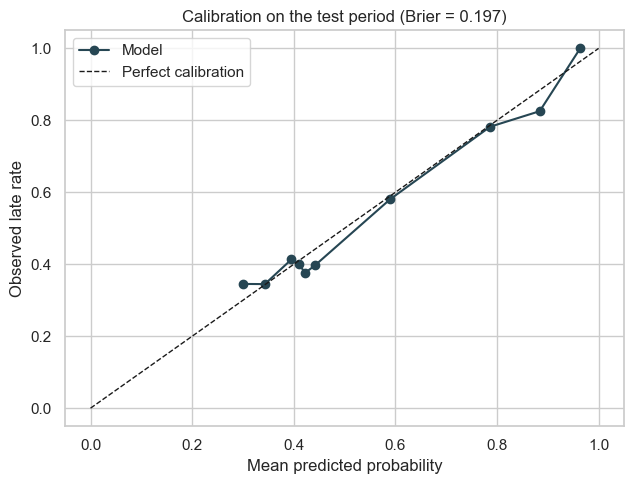

In [8]:
frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy='quantile')
plt.figure(figsize=(6.5, 5))
plt.plot(mean_pred, frac_pos, 'o-', color='#264653', label='Model')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect calibration')
plt.title(f'Calibration on the test period (Brier = {brier_score_loss(y_test, test_proba):.3f})')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed late rate'); plt.legend()
plt.tight_layout(); savefig('10_calibration'); plt.show()

## 5. Stability over time

An overall score can hide a model that works in one quarter and fails in another.

In [9]:
t = test[[DATE_COL, TARGET]].copy()
t['proba'], t['pred'] = test_proba, test_pred
t['quarter'] = t[DATE_COL].dt.to_period('Q').astype(str)

def group_metrics(g):
    out = {'orders': len(g), 'late_rate': g[TARGET].mean()}
    if g[TARGET].nunique() == 2:
        out['roc_auc'] = roc_auc_score(g[TARGET], g['proba'])
    out['precision'] = precision_score(g[TARGET], g['pred'], zero_division=0)
    out['recall'] = recall_score(g[TARGET], g['pred'], zero_division=0)
    return pd.Series(out)

by_quarter = t.groupby('quarter').apply(group_metrics).round(3)
by_quarter

,orders,late_rate,roc_auc,precision,recall
quarter,,,,,
2017Q2,11734.0,0.537,0.716,0.782,0.557
2017Q3,15812.0,0.552,0.748,0.808,0.595
2017Q4,6434.0,0.546,0.745,0.830,0.559
2018Q1,2123.0,0.563,0.751,0.825,0.589


## 6. Error analysis

Where does the model go wrong, and is it wrong more for some kinds of orders than others?

### 6.1 Performance by segment

In [10]:
seg = test[CAT].copy() if CAT else pd.DataFrame(index=test.index)
mode_cols = [c for c in NUM if c.startswith('Shipping Mode_')]
if mode_cols:
    m = pd.Series('First Class', index=test.index)
    for c in mode_cols:
        m[test[c] == 1] = c.replace('Shipping Mode_', '')
    seg['Shipping Mode'] = m

seg_cols = [c for c in ['Shipping Mode', 'Order Region', 'Department Name', 'Type'] if c in seg.columns]
tt = pd.concat([t[[TARGET, 'proba', 'pred']], seg[seg_cols]], axis=1)

segment_tables = {}
for col in seg_cols:
    tbl = tt.groupby(col).apply(group_metrics)
    tbl['flagged_share'] = tt.groupby(col)['pred'].mean()
    tbl = tbl[tbl['orders'] >= 200].sort_values('orders', ascending=False)
    segment_tables[col] = tbl
    print(f'\n--- {col} ---')
    print(tbl.head(12).round(3).to_string())


--- Shipping Mode ---
                 orders  late_rate  roc_auc  precision  recall  flagged_share
Shipping Mode                                                                
Standard Class  21553.0      0.378    0.518      0.414   0.026          0.024
Second Class     7041.0      0.761    0.571      0.761   1.000          1.000
First Class      5550.0      0.945    0.876      0.945   1.000          1.000
Same Day         1959.0      0.504    0.562      0.539   0.561          0.524

--- Order Region ---
                  orders  late_rate  roc_auc  precision  recall  flagged_share
Order Region                                                                  
Western Europe   12351.0      0.554    0.744      0.802   0.599          0.414
Central America   5271.0      0.547    0.722      0.827   0.547          0.362
Northern Europe   4360.0      0.531    0.727      0.778   0.563          0.385
Southern Europe   4192.0      0.550    0.757      0.836   0.579          0.381
South America

In [11]:
# the segments where the model misses the most late orders
rows = []
for col, tbl in segment_tables.items():
    for level, r in tbl.iterrows():
        rows.append({'segment': f'{col} = {level}', 'orders': int(r['orders']),
                     'late_rate': r['late_rate'], 'recall': r['recall'], 'precision': r['precision']})
weak = pd.DataFrame(rows).sort_values('recall').head(10)
print('Lowest-recall segments (at least 200 orders):')
weak.round(3).reset_index(drop=True)

Lowest-recall segments (at least 200 orders):


,segment,orders,late_rate,recall,precision
0,Shipping Mode = Standard Class,21553,0.378,0.026,0.414
1,Department Name = Book Shop,405,0.565,0.520,0.862
2,Department Name = Discs Shop,2026,0.544,0.524,0.814
3,Type = TRANSFER,10167,0.478,0.526,0.728
4,Order Region = Central America,5271,0.547,0.547,0.827
5,Order Region = Southeast Asia,1749,0.556,0.552,0.843
6,Order Region = Eastern Asia,1316,0.552,0.558,0.820
7,Shipping Mode = Same Day,1959,0.504,0.561,0.539
8,Order Region = Northern Europe,4360,0.531,0.563,0.778
9,Department Name = Health and Beauty,362,0.558,0.564,0.832


### 6.2 What do the missed late orders look like?

Among orders that really were late, I compare the ones the model caught (true positives) with the ones it missed (false negatives). The standardised difference shows which features separate the two groups. Large values point to the kind of order the model finds hard.

In [12]:
late_idx = (y_test == 1).values
caught = test.loc[late_idx & (test_pred == 1)]
missed = test.loc[late_idx & (test_pred == 0)]
print(f'Late orders caught: {len(caught):,} | missed: {len(missed):,}')

smd = []
for c in NUM:
    a, b = missed[c].astype(float), caught[c].astype(float)
    pooled = np.sqrt((a.var() + b.var()) / 2)
    if pooled and not np.isnan(pooled):
        smd.append((c, a.mean(), b.mean(), (a.mean() - b.mean()) / pooled))
smd = pd.DataFrame(smd, columns=['feature', 'mean_missed', 'mean_caught', 'std_diff'])
smd['abs'] = smd['std_diff'].abs()
smd.sort_values('abs', ascending=False).drop(columns='abs').head(8).round(3).reset_index(drop=True)

Late orders caught: 11,370 | missed: 8,362


,feature,mean_missed,mean_caught,std_diff
0,Shipping Mode_Standard Class,0.948,0.019,5.060
1,Days for shipment (scheduled),3.793,1.479,2.933
2,Shipping Mode_Second Class,0.000,0.471,-1.335
3,customer_orders_to_date,10.336,11.029,-0.082
4,Market_Europe,0.565,0.593,-0.056
5,order_is_weekend,0.293,0.269,0.052
6,Benefit per order,29.115,22.627,0.050
7,Market_Latam,0.273,0.252,0.046


In [13]:
if 'Shipping Mode' in seg.columns:
    comp = pd.DataFrame({
        'caught': seg.loc[caught.index, 'Shipping Mode'].value_counts(normalize=True),
        'missed': seg.loc[missed.index, 'Shipping Mode'].value_counts(normalize=True),
    }).fillna(0).round(3)
    print('Shipping-mode mix of caught vs missed late orders:')
    display(comp)

Shipping-mode mix of caught vs missed late orders:


,caught,missed
Shipping Mode,,
First Class,0.461,0.000
Same Day,0.049,0.052
Second Class,0.471,0.000
Standard Class,0.019,0.948


### 6.3 What drives the predictions

Permutation importance measures how much test ROC-AUC drops when one feature's values are shuffled. It works on the original input columns (so a one-hot group is not split into pieces) and uses held-out data. It shows what the model relies on. It does not prove what causes lateness.

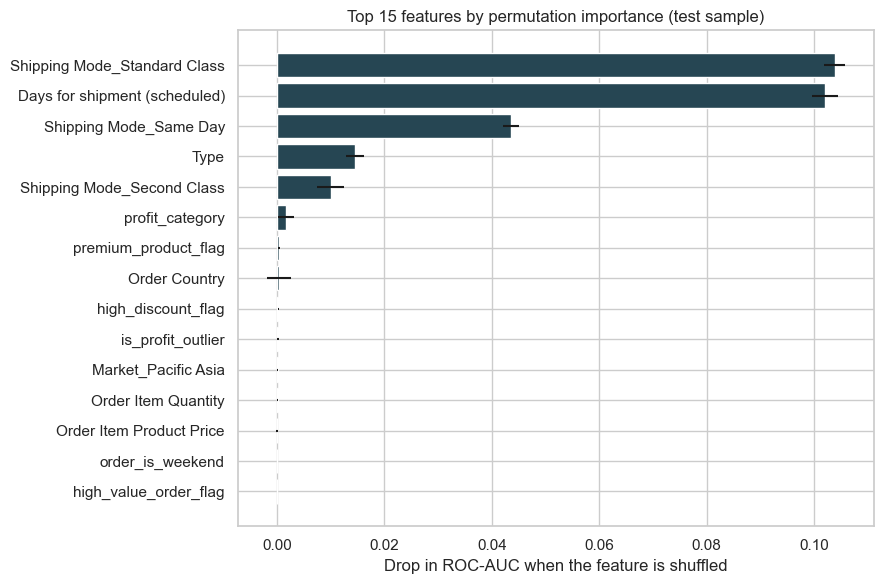

,feature,auc_drop,std
0,Shipping Mode_Standard Class,0.1038,0.0020
1,Days for shipment (scheduled),0.1020,0.0024
2,Shipping Mode_Same Day,0.0435,0.0015
3,Type,0.0145,0.0017
4,Shipping Mode_Second Class,0.0100,0.0026
5,profit_category,0.0016,0.0015
6,premium_product_flag,0.0004,0.0002
7,Order Country,0.0004,0.0022
8,high_discount_flag,0.0003,0.0001
9,is_profit_outlier,0.0002,0.0002


In [14]:
sample_idx = X_test.sample(min(8000, len(X_test)), random_state=SEED).index
pi = permutation_importance(model, X_test.loc[sample_idx], y_test.loc[sample_idx],
                            scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({'feature': FEATURES, 'auc_drop': pi.importances_mean, 'std': pi.importances_std})
         .sort_values('auc_drop', ascending=False))

top = imp.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top['feature'], top['auc_drop'], xerr=top['std'], color='#264653')
plt.title('Top 15 features by permutation importance (test sample)')
plt.xlabel('Drop in ROC-AUC when the feature is shuffled')
plt.tight_layout(); savefig('11_permutation_importance'); plt.show()
imp.head(10).round(4).reset_index(drop=True)

## 7. Business impact: how a logistics team would use the scores

Accuracy alone does not tell a team what to do on Monday morning. What matters is whether the scores let them **spend limited review effort on the orders most likely to be late**. This section shows that in three ways: a ranked review queue, an operating point, and an illustrative value estimate.

### 7.1 A ranked review queue

Suppose the team has capacity to review only a fraction of orders. Ranking orders by predicted risk and working from the top gives a better catch rate than picking orders at random. The table shows what each queue size delivers.

In [15]:
order_idx = np.argsort(-test_proba)
y_sorted = y_test.values[order_idx]
n_test, total_late, base_rate = len(y_sorted), y_sorted.sum(), y_sorted.mean()

rows = []
for k in (0.05, 0.10, 0.20, 0.30, 0.50):
    m = int(n_test * k)
    caught_k = y_sorted[:m].sum()
    rows.append({'review_top': f'{k:.0%}', 'orders_reviewed': m,
                 'share_truly_late': caught_k / m,
                 'late_orders_caught': caught_k,
                 'share_of_all_late_caught': caught_k / total_late,
                 'lift_vs_random': (caught_k / m) / base_rate})
capacity = pd.DataFrame(rows)
capacity.round(3)

,review_top,orders_reviewed,share_truly_late,late_orders_caught,share_of_all_late_caught,lift_vs_random
0,5%,1805,1.000,1805,0.091,1.830
1,10%,3610,1.000,3610,0.183,1.830
2,20%,7220,0.913,6590,0.334,1.670
3,30%,10830,0.869,9414,0.477,1.590
4,50%,18051,0.717,12945,0.656,1.312


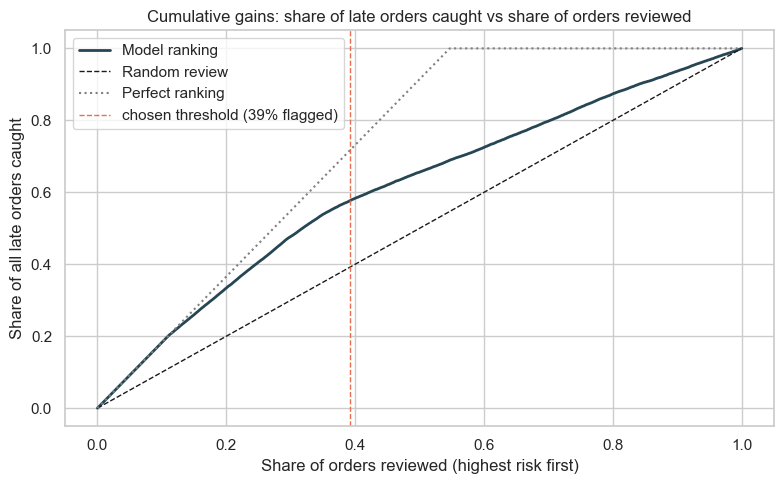

In [16]:
x = np.arange(1, n_test + 1) / n_test
gain = np.cumsum(y_sorted) / total_late
perfect = np.minimum(x / base_rate, 1.0)

plt.figure(figsize=(8, 5))
plt.plot(x, gain, color='#264653', lw=2, label='Model ranking')
plt.plot(x, x, 'k--', lw=1, label='Random review')
plt.plot(x, perfect, color='grey', ls=':', label='Perfect ranking')
plt.axvline(test_pred.mean(), color='#e76f51', ls='--', lw=1, label=f'chosen threshold ({test_pred.mean():.0%} flagged)')
plt.title('Cumulative gains: share of late orders caught vs share of orders reviewed')
plt.xlabel('Share of orders reviewed (highest risk first)'); plt.ylabel('Share of all late orders caught')
plt.legend(); plt.tight_layout(); savefig('12_cumulative_gains'); plt.show()

### 7.2 An operating point, in plain numbers

At the chosen threshold, here is what the team would see for every 1,000 orders.

In [17]:
per_1000 = 1000 / n_test
flagged_n, caught_n = int(test_pred.sum()), int(tp)
wasted_n, missed_n = int(fp), int(fn)
print(f'For every 1,000 orders placed (test period):')
print(f'  Orders flagged for action:        {flagged_n * per_1000:7.0f}')
print(f'  Of those, truly late:             {caught_n * per_1000:7.0f}   ({caught_n / flagged_n:.0%} of flags)')
print(f'  Flags on orders that were fine:   {wasted_n * per_1000:7.0f}')
print(f'  Late orders the model missed:     {missed_n * per_1000:7.0f}')
print(f'  Late orders in total:             {total_late * per_1000:7.0f}')

For every 1,000 orders placed (test period):
  Orders flagged for action:            391
  Of those, truly late:                 315   (80% of flags)
  Flags on orders that were fine:        77
  Late orders the model missed:         232
  Late orders in total:                 547


### 7.3 Illustrative value estimate

The real cost of a late order and the real success rate of an intervention are not in this dataset. I do not want to invent them and present them as facts. Instead, the cell below uses **placeholder assumptions in abstract cost units** (one review costs 1 unit) to show the reasoning. Replace the three numbers with figures from the operations team.

- `ACTION_COST`: cost of reviewing or expediting one flagged order
- `LOSS_PER_LATE`: cost of one late order if nothing is done (refund, support contact, lost repeat business)
- `SUCCESS_RATE`: share of flagged late orders where the action actually prevents the delay

Net value of a policy = (late orders caught × success rate × loss per late order) − (orders acted on × action cost).

**Break-even precision** = `ACTION_COST / (SUCCESS_RATE × LOSS_PER_LATE)`. A policy only pays off when the share of flagged orders that are truly late is above this number.

In [18]:
ACTION_COST   = 1.0     # PLACEHOLDER: replace with real figure
LOSS_PER_LATE = 5.0     # PLACEHOLDER: replace with real figure
SUCCESS_RATE  = 0.40    # PLACEHOLDER: replace with real figure

def net_value(acted, caught, action_cost=ACTION_COST, loss=LOSS_PER_LATE, success=SUCCESS_RATE):
    return caught * success * loss - acted * action_cost

break_even = ACTION_COST / (SUCCESS_RATE * LOSS_PER_LATE)
print(f'Break-even precision: {break_even:.0%}')
print(f'Model precision at chosen threshold (test): {precision_score(y_test, test_pred):.0%}')
print(f'Late rate overall (precision if every order is acted on): {base_rate:.0%}\n')

k20 = int(n_test * 0.20)
policies = {
    'No intervention':                       (0, 0),
    'Act on every order':                    (n_test, total_late),
    'Act on a random 20% of orders':         (k20, total_late * 0.20),
    'Model: top 20% by risk':                (k20, y_sorted[:k20].sum()),
    f'Model: chosen threshold ({test_pred.mean():.0%} flagged)': (flagged_n, caught_n),
}
pol = pd.DataFrame({name: {'orders_acted_on_per_1000': a * per_1000,
                           'late_caught_per_1000': c * per_1000,
                           'net_value_per_1000': net_value(a, c) * per_1000}
                    for name, (a, c) in policies.items()}).T
pol.round(1)

Break-even precision: 50%
Model precision at chosen threshold (test): 80%
Late rate overall (precision if every order is acted on): 55%



,orders_acted_on_per_1000,late_caught_per_1000,net_value_per_1000
No intervention,0.0,0.0,0.0
Act on every order,1000.0,546.5,93.1
Act on a random 20% of orders,200.0,109.3,18.6
Model: top 20% by risk,200.0,182.5,165.1
Model: chosen threshold (39% flagged),391.4,314.9,238.4


### 7.4 How sensitive is this to the assumptions?

Because the inputs are placeholders, the useful question is: *under which assumptions does the model beat simply acting on every order?* The first table shows the net value of the model at the chosen threshold. The second shows its advantage over acting on every order. A positive number means the model is the better policy.

In [19]:
succ_grid = [0.2, 0.4, 0.6]
cost_grid = [0.5, 1.0, 2.0]
v_model, v_adv = {}, {}
for s in succ_grid:
    v_model[f'success {s:.0%}'], v_adv[f'success {s:.0%}'] = {}, {}
    for c in cost_grid:
        m_v = net_value(flagged_n, caught_n, action_cost=c, success=s) * per_1000
        a_v = net_value(n_test, total_late, action_cost=c, success=s) * per_1000
        v_model[f'success {s:.0%}'][f'action cost {c}'] = m_v
        v_adv[f'success {s:.0%}'][f'action cost {c}'] = m_v - a_v

print(f'Net value per 1,000 orders, model at chosen threshold (loss per late order = {LOSS_PER_LATE}):')
display(pd.DataFrame(v_model).round(0))
print('\nAdvantage over acting on every order (positive = model is better):')
display(pd.DataFrame(v_adv).round(0))

Net value per 1,000 orders, model at chosen threshold (loss per late order = 5.0):


,success 20%,success 40%,success 60%
action cost 0.5,119.0,434.0,749.0
action cost 1.0,-77.0,238.0,553.0
action cost 2.0,-468.0,-153.0,162.0



Advantage over acting on every order (positive = model is better):


,success 20%,success 40%,success 60%
action cost 0.5,73.0,-159.0,-391.0
action cost 1.0,377.0,145.0,-86.0
action cost 2.0,986.0,754.0,522.0


### 7.5 What the team would actually see: a worklist

A sample of the highest-risk orders from the test period, in the form a planner could work through. (Outcomes are shown only because this is historical data.)

In [20]:
w = test[[DATE_COL]].copy()
if ORDER_ID:
    w.insert(0, 'order_id', test[ORDER_ID])
w['late_probability'] = test_proba.round(3)
if 'Shipping Mode' in seg.columns:
    w['shipping_mode'] = seg['Shipping Mode']
if 'Days for shipment (scheduled)' in test.columns:
    w['scheduled_days'] = test['Days for shipment (scheduled)']
for c in ('Order Region', 'Department Name'):
    if c in test.columns:
        w[c] = test[c]
w['actually_late'] = y_test.values
worklist = w.sort_values('late_probability', ascending=False).head(15).reset_index(drop=True)
worklist

,order_id,order date (DateOrders),late_probability,shipping_mode,scheduled_days,Order Region,Department Name,actually_late
0,70718,2017-10-29 07:18:00,0.976,First Class,1,Southern Europe,Technology,1
1,63087,2017-07-09 21:50:00,0.973,First Class,1,Northern Europe,Fan Shop,1
2,68296,2017-09-23 22:46:00,0.973,First Class,1,Western Europe,Fan Shop,1
3,62805,2017-07-05 19:02:00,0.973,First Class,1,Southern Europe,Fitness,1
4,64981,2017-08-06 13:23:00,0.972,First Class,1,Northern Europe,Outdoors,1
5,63290,2017-07-12 20:57:00,0.972,First Class,1,Western Europe,Footwear,1
6,66483,2017-08-28 11:36:00,0.972,First Class,1,Western Europe,Fitness,1
7,61877,2017-06-22 05:55:00,0.972,First Class,1,Western Europe,Outdoors,1
8,59436,2017-05-17 14:43:00,0.971,First Class,1,Caribbean,Fan Shop,1
9,59436,2017-05-17 14:43:00,0.971,First Class,1,Caribbean,Apparel,1


## 8. Findings

The numbers below are filled in from this run.

In [21]:
fin = results.loc[f'FINAL: {art["selected_name"]}']
rule = results.loc['Planner rule (mode + scheduled days)']
top20 = capacity.loc[capacity['review_top'] == '20%'].iloc[0]

print(f'Model: {art["selected_name"]}')
print(f'Test period: {manifest["evaluation_boundaries"]["test"]["from"]} to {manifest["evaluation_boundaries"]["test"]["to"]} '
      f'({n_test:,} orders, {base_rate:.0%} late)\n')
print(f'1. Ranking quality: ROC-AUC {fin["roc_auc"]:.3f} vs {rule["roc_auc"]:.3f} for the shipping-mode rule '
      f'(difference {fin["roc_auc"] - rule["roc_auc"]:+.3f}).')
print(f'2. At the chosen threshold the model flags {fin["flagged_share"]:.0%} of orders; {fin["precision"]:.0%} of flags are truly late '
      f'and {fin["recall"]:.0%} of all late orders are caught.')
print(f'3. Reviewing only the top 20% of orders by risk reaches {top20["share_truly_late"]:.0%} truly late orders '
      f'({top20["lift_vs_random"]:.1f}x better than random) and captures {top20["share_of_all_late_caught"]:.0%} of all late orders.')
if len(weak):
    w0 = weak.iloc[0]
    print(f'4. Weakest segment for catching late orders: {w0["segment"]} (recall {w0["recall"]:.0%}, {int(w0["orders"]):,} orders).')
print(f'5. Test performance is {"close to" if abs(precision_score(y_test, test_pred) - precision_score(y_val, val_pred)) < 0.05 else "different from"} '
      f'validation performance at the same threshold (precision {precision_score(y_val, val_pred):.0%} -> {precision_score(y_test, test_pred):.0%}).')

Model: Logistic Regression (tuned)
Test period: 2017-04-22 to 2018-01-31 (36,103 orders, 55% late)

1. Ranking quality: ROC-AUC 0.737 vs 0.727 for the shipping-mode rule (difference +0.010).
2. At the chosen threshold the model flags 39% of orders; 80% of flags are truly late and 58% of all late orders are caught.
3. Reviewing only the top 20% of orders by risk reaches 91% truly late orders (1.7x better than random) and captures 33% of all late orders.
4. Weakest segment for catching late orders: Shipping Mode = Standard Class (recall 3%, 21,553 orders).
5. Test performance is close to validation performance at the same threshold (precision 80% -> 80%).


### Recommendations for the logistics team

1. **Use the score to rank, not only to flag.** Work the queue from the highest-risk order downward. The capacity table in 7.1 shows what each queue size delivers, so the team can pick a size that matches its staffing.
2. **Tie the threshold to a written rule.** The 80% precision rule is a starting point. Agree the real tolerance for false alarms with operations, rerun section 2 and the rest follows.
3. **Review shipping-mode promises where late rates are high.** The segment tables in 6.1 show which modes and regions have the highest late rates. Where a short scheduled-days promise is routinely missed, changing the promise is a process fix that no model can replace.
4. **Plan for the hard cases.** Section 6.2 shows what the missed late orders look like. These are the orders that a rule or a manual check should cover.
5. **Monitor after launch.** Track the share of orders flagged, the late rate among flagged orders, and ROC-AUC by quarter (section 5). Retrain if they drift.
6. **Add the missing data.** Carrier capacity, weather and warehouse load are not in this dataset and are the most likely sources of further improvement.

## 9. Save the final model and the evaluation reports

In [22]:
final_artifact = {
    'pipeline': model,
    'threshold': THRESHOLD,
    'target_precision': TARGET_PRECISION,
    'selected_name': art['selected_name'],
    'best_params': art['best_params'],
    'features': FEATURES,
    'numeric_features': NUM,
    'categorical_features': CAT,
    'target': TARGET,
    'validation_metrics': art['validation_metrics'],
    'test_metrics': {k: float(v) for k, v in fin.items()},
    'business_assumptions': {'action_cost': ACTION_COST, 'loss_per_late_order': LOSS_PER_LATE,
                             'success_rate': SUCCESS_RATE, 'note': 'placeholders, replace with real figures'},
    'sklearn_version': sklearn.__version__,
    'trained_on': art['trained_on'],
    'tested_on': manifest['evaluation_boundaries']['test'],
}
joblib.dump(final_artifact, MODEL_DIR / 'late_delivery_model.joblib')

with open(REPORT_DIR / 'metrics.json', 'w') as f:
    json.dump({k: v for k, v in final_artifact.items() if k != 'pipeline'}, f, indent=2, default=str)
results.round(4).to_csv(REPORT_DIR / 'model_comparison.csv')
capacity.round(4).to_csv(REPORT_DIR / 'review_queue_capacity.csv', index=False)
by_quarter.to_csv(REPORT_DIR / 'performance_by_quarter.csv')
imp.to_csv(REPORT_DIR / 'feature_importance.csv', index=False)
worklist.to_csv(REPORT_DIR / 'sample_worklist.csv', index=False)
print('Saved:', MODEL_DIR / 'late_delivery_model.joblib')
print('Reports written to:', REPORT_DIR)

Saved: E:\Supply Chain Project\Models\late_delivery_model.joblib
Reports written to: E:\Supply Chain Project\Reports


### Using the saved model

A small function that takes new orders (same columns as the model features) and returns a risk score and a flag at the chosen threshold.

In [23]:
def predict_late_risk(orders: pd.DataFrame, model_path=MODEL_DIR / 'late_delivery_model.joblib') -> pd.DataFrame:
    a = joblib.load(model_path)
    missing = [c for c in a['features'] if c not in orders.columns]
    if missing:
        raise ValueError(f'Missing required columns: {missing}')
    proba = a['pipeline'].predict_proba(orders[a['features']])[:, 1]
    return pd.DataFrame({
        'late_probability': proba.round(4),
        'flag_for_review':  (proba >= a['threshold']).astype(int),
    }, index=orders.index)

demo = X_test.head(8)
pd.concat([predict_late_risk(demo), y_test.head(8).rename('actual_late')], axis=1)

,late_probability,flag_for_review,actual_late
144416,0.2976,0,0
144417,0.4154,0,0
144418,0.4035,0,0
144419,0.4128,0,0
144420,0.4058,0,0
144421,0.4036,0,0
144422,0.4016,0,0
144423,0.4102,0,0


## Limitations

- The 80% precision target and the cost figures in section 7 are assumptions. The conclusions that depend on them (threshold, net value) must be re-run with real figures.
- The data covers 2015–2018 from one company. A deployed model would need drift monitoring and periodic retraining.
- The model was fitted on the training period only. A production version would be refitted on all available history with the threshold re-checked.
- Feature importance describes what the model uses, not what causes lateness.